# e1 · GARCH and GARCH-MIDAS Evaluation

This notebook tests whether the BAA10Y long-run component of GARCH-MIDAS improves one-month-ahead realised-variance forecasts over GARCH(1,1), and shows how the BAA10Y coefficient θ moves across forecast origins. The forecasts and θ come from `b1_garch_garchmidas.ipynb`.

**Tests:**
GARCH-MIDAS reduces to GARCH(1,1) when θ = 0, so the pair is nested (`a` contains `b`). MSE on log RV uses Clark-West. QLIKE uses Diebold-Mariano, which is undersized for nested models, so we only use its p-values as supporting evidence and read them with caution. For both, the loss differential is tested per ETF and, for the pooled result, averaged across ETFs each month, with Newey-West standard errors (lag set by the Andrews (1991) rule). p-values are one-sided, H1: `a` beats `b`.

Note that Clark-West was derived for linear models estimated by OLS, so applying it to GARCH-MIDAS, estimated by maximum likelihood, is an approximation.

Output in `models/forecasting/results/`: `e1_losses.csv`, `e1_evaluation.csv`. `gain_t > 0` favours `a`. `loss_ratio` is `a`'s loss over `b`'s. `pct_change` is the ratio as a % change. The Clark-West statistic adjusts for nesting, so it can be significant while the ratio is above 1. We will primarily look at MSE on log RV with Clark-West results.

In [1]:
import sys
from pathlib import Path

_checkout = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "models" / "research_config.py").is_file()),
    None,
)
if _checkout is None:
    raise FileNotFoundError("Start the notebook kernel from within this project checkout.")
sys.path.insert(0, str(_checkout / "models"))
from utils.paths import PROJECT_ROOT, MODELS_DIR, DATASET_DIR, FORECAST_DIR, FORECAST_RESULTS_DIR

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

FC_DIR = FORECAST_DIR
RESULTS_DIR = FORECAST_RESULTS_DIR
os.makedirs(RESULTS_DIR, exist_ok=True)

from research_config import BLOCKS, TICKERS
block = BLOCKS["B1"]
pairs = [(pair, a, b) for pair, a, b, _ in block["pairs"]]
df = pd.read_csv(os.path.join(FC_DIR, "garch_forecasts.csv"), parse_dates=["date"])
theta = pd.read_csv(os.path.join(FC_DIR, "garchmidas_theta_by_origin.csv"), parse_dates=["date"])

In [2]:
def andrews_bandwidth(x):
    x = np.asarray(x, float); n = len(x); xd = x - x.mean()
    den = float(xd[:-1] @ xd[:-1])
    rho = 0.0 if den <= 0 else float(xd[1:] @ xd[:-1]) / den
    rho = min(max(rho, -0.97), 0.97)
    a1 = 4.0 * rho ** 2 / ((1 - rho) ** 2 * (1 + rho) ** 2)
    return 0 if a1 <= 0 else int(min(np.floor(1.1447 * (a1 * n) ** (1 / 3)), n // 4))


def newey_west_lrv(x, lag):
    x = np.asarray(x, float); n = len(x); xd = x - x.mean()
    lag = max(0, min(lag, n - 1)); s = float(xd @ xd) / n
    for l in range(1, lag + 1):
        s += 2.0 * (1.0 - l / (lag + 1.0)) * float(xd[l:] @ xd[:-l]) / n
    return max(s, 1e-16)


def hac_t(d):
    "t-statistic of mean(d) with a Newey-West variance."
    d = np.asarray(d, float)
    return d.mean() / np.sqrt(newey_west_lrv(d, andrews_bandwidth(d)) / len(d))


def qlike(rv, fc):
    r = rv / fc
    return r - np.log(r) - 1

## Losses

Common sample: the (ETF, month) rows where both models have a forecast.

In [3]:
models = block["models"]
d = df[df["model"].isin(models)].copy()
d = d[d.groupby(["etf", "date"])["model"].transform("nunique") == len(models)]
d["MSE_log"] = (d["actual_logRV"] - d["fc_log"]) ** 2
d["MSE_level"] = (d["actual_RV"] - d["fc_level"]) ** 2
d["QLIKE"] = qlike(d["actual_RV"], d["fc_level"])
print(f"{d['date'].min():%Y-%m} to {d['date'].max():%Y-%m}, {len(d)} rows")

LOSSES = ["QLIKE", "MSE_log", "MSE_level"]
per_etf = d.groupby(["model", "etf"])[LOSSES].mean().reset_index()
pooled = d.groupby("model")[LOSSES].mean().reset_index().assign(etf="pooled")
losses = pd.concat([per_etf, pooled], ignore_index=True).rename(columns={"etf": "ETF"})
losses.to_csv(os.path.join(RESULTS_DIR, "e1_losses.csv"), index=False)
losses[losses["ETF"] == "pooled"].set_index("model")[LOSSES].round(4)

2008-02 to 2025-11, 2140 rows


,QLIKE,MSE_log,MSE_level
model,,,
garch,0.2635,0.4736,0.0001
garch_midas_baa10y,0.2682,0.4826,0.0001


## Tests

In [4]:
def one_sided_p(t):
    return float(1 - norm.cdf(t))


loss_idx = losses.set_index(["model", "ETF"])
rows = []
for pair_id, a, b in pairs:
    A = d[d["model"] == a].set_index(["date", "etf"])
    B = d[d["model"] == b].set_index(["date", "etf"])
    dm_diff = A["QLIKE"] - B["QLIKE"]   # negative favours a
    # Clark-West adjusted differential; positive favours a
    cw = B["MSE_log"] - (A["MSE_log"] - (B["fc_log"] - A["fc_log"]) ** 2)

    for etf in ["pooled"] + TICKERS:
        if etf == "pooled":
            dm_t, cw_t = dm_diff.groupby("date").mean(), cw.groupby("date").mean()
        else:
            dm_t, cw_t = dm_diff.xs(etf, level="etf"), cw.xs(etf, level="etf")
        for loss, test, t in [("QLIKE", "DM", -hac_t(dm_t)), ("MSE_log", "Clark-West", hac_t(cw_t))]:
            rows.append({
                "pair": pair_id, "a": a, "b": b, "ETF": etf, "loss": loss, "test": test,
                "loss_ratio": loss_idx.loc[(a, etf), loss] / loss_idx.loc[(b, etf), loss],
                "gain_t": t, "p_value": one_sided_p(t),
            })

tests = pd.DataFrame(rows)
tests["pct_change"] = (tests["loss_ratio"] - 1) * 100   # negative: a has the lower loss
tests.to_csv(os.path.join(RESULTS_DIR, "e1_evaluation.csv"), index=False)
tests[tests["ETF"] == "pooled"].drop(columns="ETF").round(4).reset_index(drop=True)

,pair,a,b,loss,test,loss_ratio,gain_t,p_value,pct_change
0,B1.1,garch_midas_baa10y,garch,QLIKE,DM,1.0178,-1.7413,0.9592,1.7775
1,B1.1,garch_midas_baa10y,garch,MSE_log,Clark-West,1.0191,1.3270,0.0922,1.9107


## By sector tests (exploratory)

In [5]:
SECTORS = {"XLB": "Materials", "XLE": "Energy", "XLF": "Financials", "XLI": "Industrials", "XLY": "Cons. Disc."}


def fmt_p(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"


def by_sector(loss):
    t = tests[tests["loss"] == loss].copy()
    t["cell"] = [f"{r:.2f} ({fmt_p(p)})" for r, p in zip(t["loss_ratio"], t["p_value"])]
    t["row"] = t["pair"] + ": " + t["a"] + " vs " + t["b"]
    table = t.pivot(index="row", columns="ETF", values="cell")[TICKERS + ["pooled"]]
    table.columns = [f"{c} {SECTORS[c]}" for c in TICKERS] + ["Pooled"]
    return table.rename_axis(None)


for loss, test in [("MSE_log", "Clark-West"), ("QLIKE", "DM")]:
    print(f"{loss}: ratio (p-value), {test}")
    display(by_sector(loss))

MSE_log: ratio (p-value), Clark-West


,XLB Materials,XLE Energy,XLF Financials,XLI Industrials,XLY Cons. Disc.,Pooled
B1.1: garch_midas_baa10y vs garch,1.01 (0.358),1.03 (0.503),1.01 (0.337),1.03 (0.168),1.02 (0.260),1.02 (0.092)


QLIKE: ratio (p-value), DM


,XLB Materials,XLE Energy,XLF Financials,XLI Industrials,XLY Cons. Disc.,Pooled
B1.1: garch_midas_baa10y vs garch,0.99 (0.285),1.03 (0.901),1.02 (0.948),1.03 (0.794),1.02 (0.912),1.02 (0.959)


**Reading.**
* **No significant gain.** Clark-West does not reject at the 5% level for any ETF or pooled. The pooled result is marginal (p = 0.092), and no individual ETF comes close (p ≥ 0.168).
* **A higher loss is not evidence of a worse model.** GARCH-MIDAS has a slightly higher loss than GARCH for all five ETFs on MSE on log RV, and for four of five on QLIKE (the exception is XLB). For a nested pair this is expected when the spread carries little or no information, because estimating θ adds noise to the forecast. The DM p-values on QLIKE are therefore not read as evidence that GARCH-MIDAS is worse, and an insignificant result does not show that the two models are equally accurate. The result is no significant gain from the credit spread.

## By-sector percentage changes

Percentage change in mean loss for GARCH-MIDAS relative to GARCH: $100 \times (\mathrm{loss\ ratio}-1)$. Negative values mean lower loss for GARCH-MIDAS; positive values mean higher loss. The pooled row averages across the five ETFs.

In [6]:
MODEL_NAMES = {"garch": "GARCH(1,1)", "garch_midas_baa10y": "GARCH-MIDAS (BAA10Y)"}

for pair_id, a, b in pairs:
    sector_pct_change = (
        tests.loc[tests["pair"].eq(pair_id)]
        .pivot(index="ETF", columns="loss", values="pct_change")
        .reindex(index=TICKERS + ["pooled"], columns=["MSE_log", "QLIKE"])
        .rename(columns={"MSE_log": "Log MSE"})
    )
    sector_pct_change.index = pd.Index(
        [f"{ticker} {SECTORS[ticker]}" for ticker in TICKERS] + ["Pooled"],
        name="Sector ETF",
    )
    print(f"{pair_id}: {MODEL_NAMES[a]} relative to {MODEL_NAMES[b]}")
    display(sector_pct_change.map(lambda value: f"{value:+.2f}%"))


B1.1: GARCH-MIDAS (BAA10Y) relative to GARCH(1,1)


loss,Log MSE,QLIKE
Sector ETF,,
XLB Materials,+1.45%,-1.25%
XLE Energy,+2.56%,+3.45%
XLF Financials,+0.60%,+1.95%
XLI Industrials,+3.44%,+2.66%
XLY Cons. Disc.,+1.88%,+1.87%
Pooled,+1.91%,+1.78%


## θ across forecast origins

θ is estimated separately for each ETF at each of the 214 monthly refits. It is the effect of a one-standard-deviation rise in BAA10Y (standard deviation measured over the estimation window) on the log of the long-run variance component τ: τ is multiplied by $e^{\theta}$. Under the economic hypothesis θ > 0, since a wider credit spread should raise long-run variance.

,mean,min,max,positive,sign_changes,largest_monthly_change
ETF,,,,,,
XLB,0.140,-0.011,0.458,213/214,2,0.289
XLE,-0.304,-0.416,-0.151,0/214,0,0.141
XLF,0.011,-0.425,0.186,117/214,5,0.206
XLI,0.346,0.107,0.750,214/214,0,0.588
XLY,0.127,-0.100,0.693,191/214,9,0.433


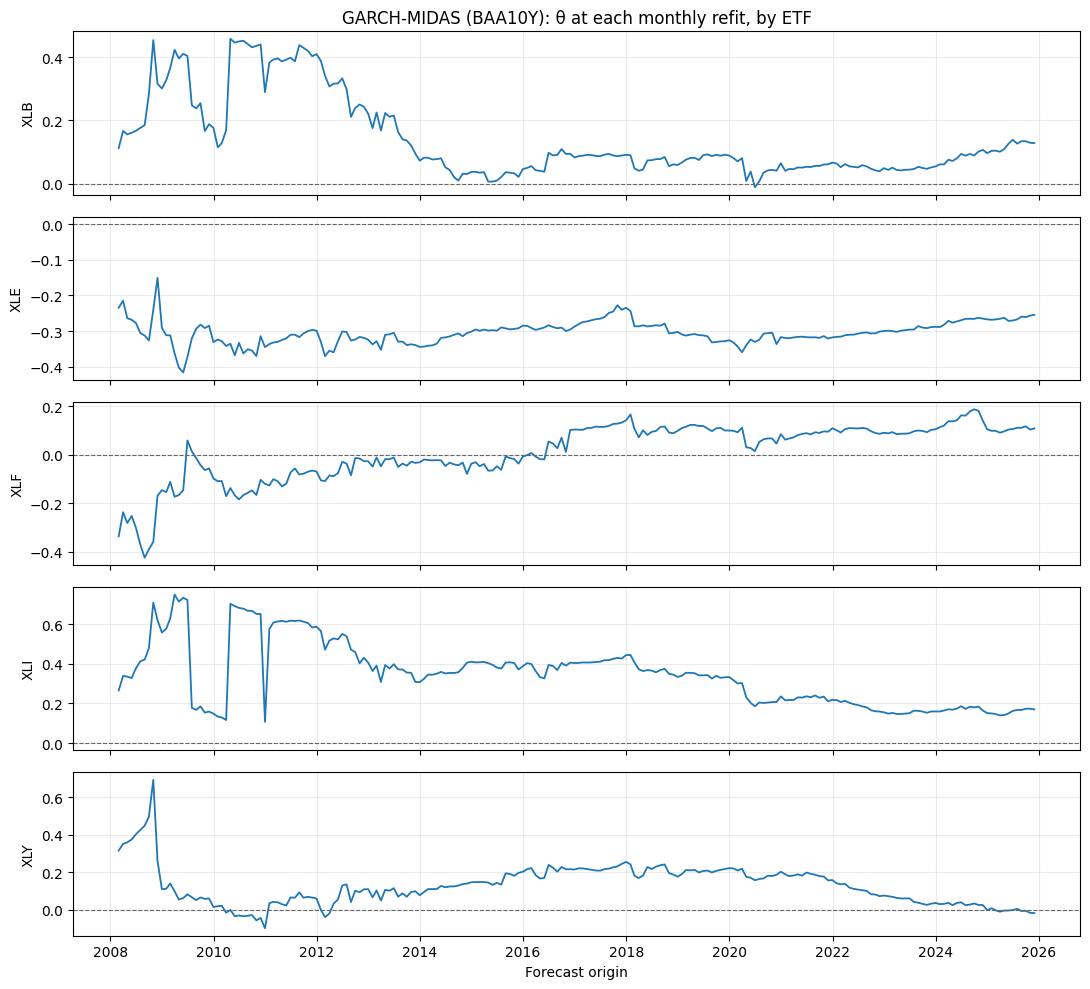

In [7]:
rows = []
for etf in TICKERS:
    th = theta[theta["etf"] == etf].sort_values("date")["theta"].to_numpy()
    rows.append({"ETF": etf, "mean": th.mean(), "min": th.min(), "max": th.max(),
                 "positive": f"{(th > 0).sum()}/{len(th)}",
                 "sign_changes": int((np.sign(th[1:]) != np.sign(th[:-1])).sum()),
                 "largest_monthly_change": np.abs(np.diff(th)).max()})
display(pd.DataFrame(rows).set_index("ETF").round(3))

fig, axes = plt.subplots(len(TICKERS), 1, figsize=(11, 10), sharex=True)
for ax, etf in zip(axes, TICKERS):
    t = theta[theta["etf"] == etf].sort_values("date")
    ax.plot(t["date"], t["theta"], lw=1.3)
    ax.axhline(0, color="0.4", lw=0.8, ls="--")
    ax.set_ylabel(etf)
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Forecast origin")
axes[0].set_title("GARCH-MIDAS (BAA10Y): θ at each monthly refit, by ETF")
fig.tight_layout()
plt.show()

* **θ never changes sign for XLI or XLE.** It is positive at every origin for XLI, as the hypothesis predicts, and negative at every origin for XLE, against it.
* **For XLB, XLY and XLF the effect is small on average.** Their mean θ is +0.14, +0.13 and +0.01. XLB's is positive at 213 of 214 origins, while XLY's and XLF's change sign 9 and 5 times. XLF's θ is mostly negative before 2016 and mostly positive after.
* **The estimates for XLI and XLB are unstable in 2009–2011.** XLI's θ jumps four times between levels near 0.15 and 0.6 to 0.75 (largest one-month change 0.59, in April 2010). XLB's moves on the same dates, by less (0.09 to 0.29).

The effect of the credit spread therefore differs in sign across sectors, changes sign over time for XLY and XLF, and is unstable for XLI and XLB in 2009–2011. This is consistent with the absence of a significant forecasting gain.